<a href="https://colab.research.google.com/github/namratapathak0410-pixel/Label-Efficient-Representation-Learning-SSL/blob/main/plantVillage.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

%pip install -q kaggle


In [2]:

# Download the PlantVillage dataset from Kaggle

from pathlib import Path
import subprocess

DATA_DIR = Path("/content/plantvillage-data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

DATASET_SLUG = "abdallahalidev/plantvillage-dataset"

result = subprocess.run(
    [
        "kaggle", "datasets", "download",
        "-d", DATASET_SLUG,
        "-p", str(DATA_DIR),
        "--unzip",
    ],
    text=True,
    capture_output=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError(
        "Kaggle download failed. Check API credentials and dataset access."
    )

print("\nDownload and extraction completed.")
print("Files are in:", DATA_DIR)


Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0



Download and extraction completed.
Files are in: /content/plantvillage-data


In [4]:

# Locate the directory containing disease-class folders

from pathlib import Path

ROOT = Path("/content/plantvillage-data")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

candidates = []

for folder in [ROOT, *ROOT.rglob("*")]:
    if not folder.is_dir():
        continue

    try:
        child_dirs = [p for p in folder.iterdir() if p.is_dir()]
    except OSError:
        continue

    image_children = []

    for child in child_dirs:
        try:
            if any(
                p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
                for p in child.iterdir()
            ):
                image_children.append(child)
        except OSError:
            continue

    if len(image_children) >= 10:
        candidates.append((folder, len(image_children)))

print("Possible class-root directories:")

for folder, n in sorted(
    candidates, key=lambda item: item[1], reverse=True
):
    print(f"{n} image-containing folders: {folder}")


Possible class-root directories:
38 image-containing folders: /content/plantvillage-data/plantvillage dataset/grayscale
38 image-containing folders: /content/plantvillage-data/plantvillage dataset/segmented
38 image-containing folders: /content/plantvillage-data/plantvillage dataset/color


Print the detected class directories

In [5]:

from pathlib import Path

ROOT = Path("/content/plantvillage-data")

print("Dataset directory exists:", ROOT.exists())

if ROOT.exists():
    print("\nTop-level contents:")
    for item in ROOT.iterdir():
        print(("[DIR] " if item.is_dir() else "[FILE] ") + str(item))

    print("\nPossible class directories:")
    for folder in ROOT.rglob("*"):
        if not folder.is_dir():
            continue

        try:
            image_count = sum(
                1 for p in folder.iterdir()
                if p.is_file()
                and p.suffix.lower() in {
                    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
                }
            )
        except OSError:
            continue

        if image_count > 0:
            print(f"{image_count:5d} images | {folder}")


Dataset directory exists: True

Top-level contents:
[DIR] /content/plantvillage-data/plantvillage dataset

Possible class directories:
  985 images | /content/plantvillage-data/plantvillage dataset/grayscale/Corn_(maize)___Northern_Leaf_Blight
 1771 images | /content/plantvillage-data/plantvillage dataset/grayscale/Tomato___Septoria_leaf_spot
 1645 images | /content/plantvillage-data/plantvillage dataset/grayscale/Apple___healthy
 1109 images | /content/plantvillage-data/plantvillage dataset/grayscale/Strawberry___Leaf_scorch
 1000 images | /content/plantvillage-data/plantvillage dataset/grayscale/Potato___Early_blight
  997 images | /content/plantvillage-data/plantvillage dataset/grayscale/Pepper,_bell___Bacterial_spot
 1478 images | /content/plantvillage-data/plantvillage dataset/grayscale/Pepper,_bell___healthy
  621 images | /content/plantvillage-data/plantvillage dataset/grayscale/Apple___Black_rot
 1383 images | /content/plantvillage-data/plantvillage dataset/grayscale/Grape___Es

Run the final dataset audit

Dataset: /content/plantvillage-data/plantvillage dataset/color
Class folders found: 38
Starting image validation and duplicate checks...
This may take a few minutes for the full dataset.

Processed class 1/38: Apple___Apple_scab
Processed class 2/38: Apple___Black_rot
Processed class 3/38: Apple___Cedar_apple_rust
Processed class 4/38: Apple___healthy
Processed class 5/38: Blueberry___healthy
Processed class 6/38: Cherry_(including_sour)___Powdery_mildew
Processed class 7/38: Cherry_(including_sour)___healthy
Processed class 8/38: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Processed class 9/38: Corn_(maize)___Common_rust_
Processed class 10/38: Corn_(maize)___Northern_Leaf_Blight
Processed class 11/38: Corn_(maize)___healthy
Processed class 12/38: Grape___Black_rot
Processed class 13/38: Grape___Esca_(Black_Measles)
Processed class 14/38: Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Processed class 15/38: Grape___healthy
Processed class 16/38: Orange___Haunglongbing_(Citrus_green

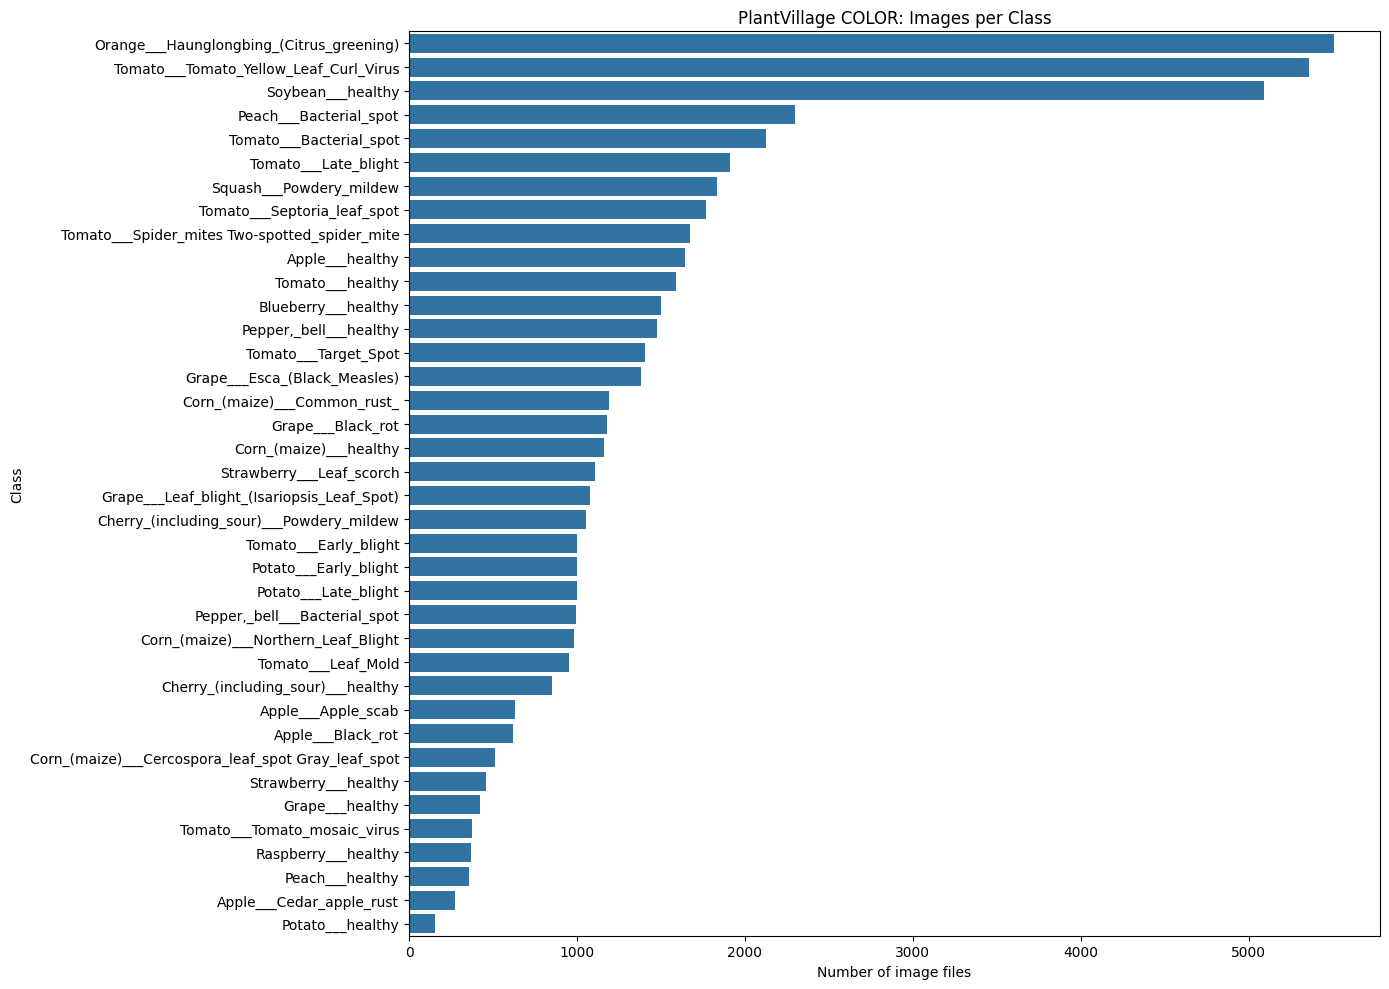

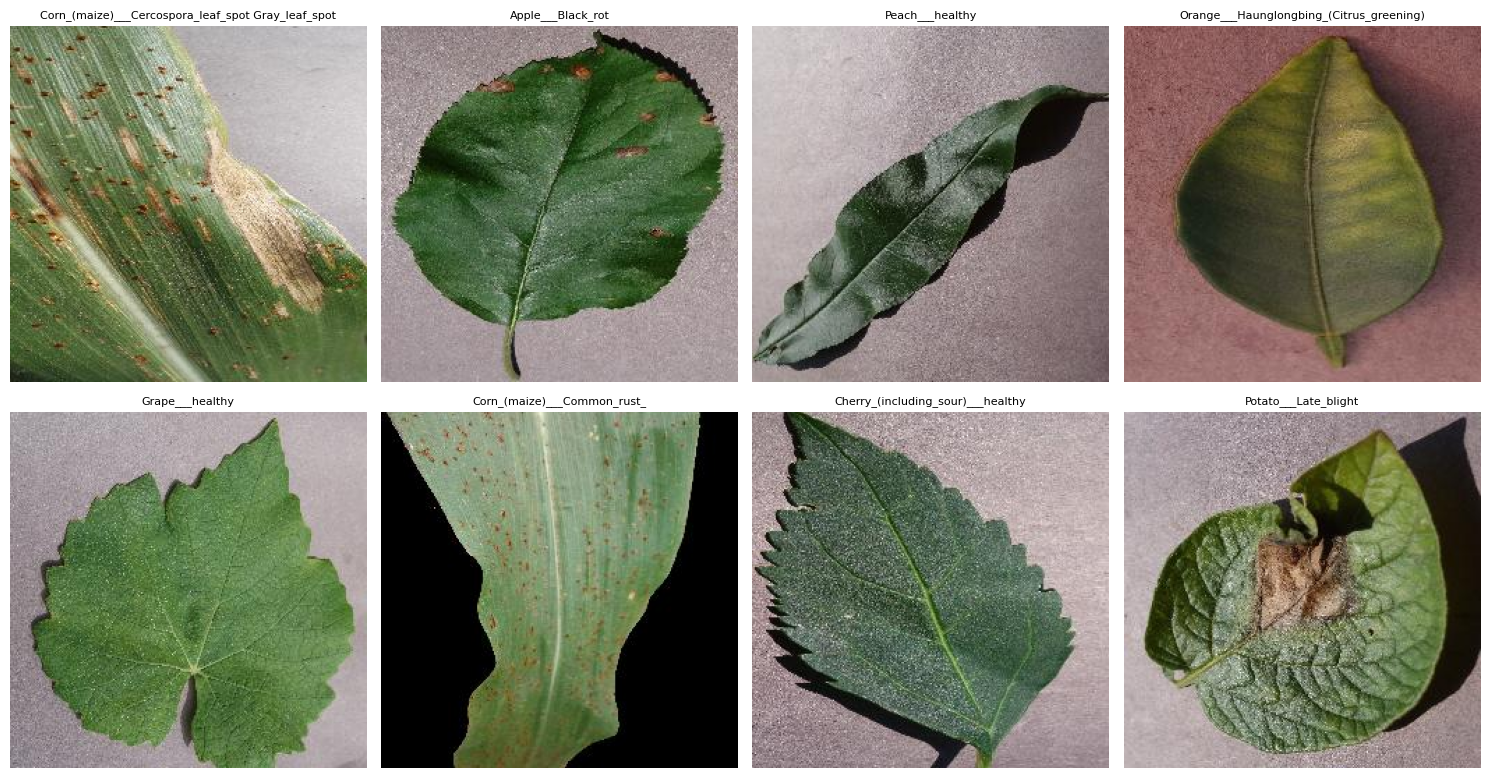


Audit reports saved in: /content/plantvillage-ssl
Manifest: data/manifests/color_dataset_manifest.csv
Class counts: results/metrics/class_distribution.csv
Corrupted images: results/metrics/corrupted_images.csv
Exact duplicates: results/metrics/exact_duplicates.csv


In [6]:

# CELL 7: PlantVillage COLOR dataset audit
# Run this cell in Google Colab.

from pathlib import Path
from collections import Counter, defaultdict
from PIL import Image
import hashlib
import random
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

CLASS_ROOT = Path(
    "/content/plantvillage-data/plantvillage dataset/color"
)

PROJECT_ROOT = Path("/content/plantvillage-ssl")
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"
}

if not CLASS_ROOT.is_dir():
    raise FileNotFoundError(f"Class directory not found: {CLASS_ROOT}")

( PROJECT_ROOT / "data/manifests").mkdir(parents=True, exist_ok=True)
( PROJECT_ROOT / "results/metrics").mkdir(parents=True, exist_ok=True)
( PROJECT_ROOT / "results/plots").mkdir(parents=True, exist_ok=True)

class_dirs = sorted(
    p for p in CLASS_ROOT.iterdir() if p.is_dir()
)

if not class_dirs:
    raise ValueError("No class folders found inside COLOR directory.")

records = []
corrupted = []
hash_to_paths = defaultdict(list)

print("Dataset:", CLASS_ROOT)
print("Class folders found:", len(class_dirs))
print("Starting image validation and duplicate checks...")
print("This may take a few minutes for the full dataset.\n")

for class_index, class_dir in enumerate(class_dirs, start=1):
    image_paths = sorted(
        p for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    for path in image_paths:
        valid = False
        width, height, mode = None, None, None
        file_hash = None
        error_message = ""

        try:
            with Image.open(path) as img:
                img.verify()

            with Image.open(path) as img:
                width, height = img.size
                mode = img.mode

            digest = hashlib.sha256()

            with path.open("rb") as f:
                for chunk in iter(lambda: f.read(1024 * 1024), b""):
                    digest.update(chunk)

            file_hash = digest.hexdigest()
            hash_to_paths[file_hash].append(str(path))
            valid = True

        except Exception as exc:
            error_message = str(exc)
            corrupted.append({
                "path": str(path),
                "error": error_message
            })

        records.append({
            "path": str(path),
            "relative_path": str(path.relative_to(CLASS_ROOT)),
            "class_name": class_dir.name,
            "valid": valid,
            "width": width,
            "height": height,
            "mode": mode,
            "sha256": file_hash,
            "error": error_message
        })

    print(f"Processed class {class_index}/{len(class_dirs)}: {class_dir.name}")

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No supported image files were found.")

# Summary
class_counts = (
    df.groupby("class_name")
      .agg(
          total_files=("path", "size"),
          readable_images=("valid", "sum")
      )
      .sort_values("total_files", ascending=False)
)

duplicate_groups = [
    paths for paths in hash_to_paths.values()
    if len(paths) > 1
]

print("\n" + "=" * 55)
print("PLANTVILLAGE COLOR DATASET AUDIT")
print("=" * 55)
print("Total image files:", len(df))
print("Readable images:", int(df["valid"].sum()))
print("Corrupted/unreadable images:", len(corrupted))
print("Number of class folders:", len(class_dirs))
print("Expected classes in standard PlantVillage:", 38)
print("Exact duplicate groups:", len(duplicate_groups))
print("Files involved in exact duplicates:",
      sum(len(g) for g in duplicate_groups))

print("\nImage modes:")
print(df.loc[df["valid"], "mode"].value_counts())

print("\nClass distribution:")
print(class_counts.to_string())

# Save manifest and class counts
df.to_csv(
    PROJECT_ROOT / "data/manifests/color_dataset_manifest.csv",
    index=False
)

class_counts.to_csv(
    PROJECT_ROOT / "results/metrics/class_distribution.csv"
)

# Save corrupted files
pd.DataFrame(
    corrupted,
    columns=["path", "error"]
).to_csv(
    PROJECT_ROOT / "results/metrics/corrupted_images.csv",
    index=False
)

# Save duplicate report
duplicate_rows = []

for group_id, paths in enumerate(duplicate_groups, start=1):
    for path in paths:
        duplicate_rows.append({
            "duplicate_group": group_id,
            "path": path
        })

pd.DataFrame(
    duplicate_rows,
    columns=["duplicate_group", "path"]
).to_csv(
    PROJECT_ROOT / "results/metrics/exact_duplicates.csv",
    index=False
)

# Plot class distribution
plot_data = class_counts.reset_index()

plt.figure(figsize=(14, 10))
sns.barplot(
    data=plot_data,
    x="total_files",
    y="class_name"
)
plt.title("PlantVillage COLOR: Images per Class")
plt.xlabel("Number of image files")
plt.ylabel("Class")
plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "results/plots/class_distribution.png",
    dpi=160
)
plt.show()

# Display one valid sample per selected class
rng = random.Random(42)
valid_df = df[df["valid"]]

sample_classes = rng.sample(
    list(valid_df["class_name"].unique()),
    min(8, valid_df["class_name"].nunique())
)

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()

for ax, class_name in zip(axes, sample_classes):
    sample = valid_df[valid_df["class_name"] == class_name].sample(
        n=1, random_state=42
    ).iloc[0]

    with Image.open(sample["path"]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name, fontsize=8)
    ax.axis("off")

for ax in axes[len(sample_classes):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "results/plots/sample_images.png",
    dpi=160
)
plt.show()

print("\nAudit reports saved in:", PROJECT_ROOT)
print("Manifest: data/manifests/color_dataset_manifest.csv")
print("Class counts: results/metrics/class_distribution.csv")
print("Corrupted images: results/metrics/corrupted_images.csv")
print("Exact duplicates: results/metrics/exact_duplicates.csv")


Check the expected number of classes

In [7]:

from pathlib import Path

CLASS_ROOT = Path(
    "/content/plantvillage-data/plantvillage dataset/color"
)

classes = sorted(
    p.name for p in CLASS_ROOT.iterdir() if p.is_dir()
)

print("Number of classes:", len(classes))
print("\nClass names:")
for i, name in enumerate(classes, start=1):
    print(f"{i:02d}. {name}")

print("\nExpected standard class count: 38")
print("Class count matches:", len(classes) == 38)


Number of classes: 38

Class names:
01. Apple___Apple_scab
02. Apple___Black_rot
03. Apple___Cedar_apple_rust
04. Apple___healthy
05. Blueberry___healthy
06. Cherry_(including_sour)___Powdery_mildew
07. Cherry_(including_sour)___healthy
08. Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
09. Corn_(maize)___Common_rust_
10. Corn_(maize)___Northern_Leaf_Blight
11. Corn_(maize)___healthy
12. Grape___Black_rot
13. Grape___Esca_(Black_Measles)
14. Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
15. Grape___healthy
16. Orange___Haunglongbing_(Citrus_greening)
17. Peach___Bacterial_spot
18. Peach___healthy
19. Pepper,_bell___Bacterial_spot
20. Pepper,_bell___healthy
21. Potato___Early_blight
22. Potato___Late_blight
23. Potato___healthy
24. Raspberry___healthy
25. Soybean___healthy
26. Squash___Powdery_mildew
27. Strawberry___Leaf_scorch
28. Strawberry___healthy
29. Tomato___Bacterial_spot
30. Tomato___Early_blight
31. Tomato___Late_blight
32. Tomato___Leaf_Mold
33. Tomato___Septoria_leaf_spot


Verify the image counts and audit files

In [8]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/plantvillage-ssl")
manifest_path = PROJECT_ROOT / "data/manifests/color_dataset_manifest.csv"

if manifest_path.exists():
    df = pd.read_csv(manifest_path)

    print("Total manifest rows:", len(df))
    print("Readable images:", int(df["valid"].sum()))
    print("Unreadable images:", int((~df["valid"]).sum()))
    print("Classes in manifest:", df["class_name"].nunique())
    print("Duplicate file hashes:", int(
        df.loc[df["valid"], "sha256"].duplicated(keep=False).sum()
    ))

    print("\nAudit summary:")
    print("Total image files:", len(df))
    print("Expected classes:", 38)
    print("Class count matches:", df["class_name"].nunique() == 38)

else:
    print("Manifest not found.")
    print("Check whether the complete audit cell finished successfully.")


Total manifest rows: 54305
Readable images: 54305
Unreadable images: 0
Classes in manifest: 38
Duplicate file hashes: 42

Audit summary:
Total image files: 54305
Expected classes: 38
Class count matches: True


Check for metadata and duplicate information

In [9]:

from pathlib import Path

ROOT = Path("/content/plantvillage-data/plantvillage dataset")

print("Top-level dataset files:")

for path in ROOT.iterdir():
    if path.is_file():
        print(path.name)

print("\nPotential metadata files:")

for path in ROOT.rglob("*"):
    if path.is_file() and path.suffix.lower() in {
        ".csv", ".json", ".parquet", ".tsv", ".txt"
    }:
        print(path.relative_to(ROOT))


Top-level dataset files:

Potential metadata files:


In [10]:

from pathlib import Path
import pandas as pd

manifest_path = Path(
    "/content/plantvillage-ssl/data/manifests/color_dataset_manifest.csv"
)

if manifest_path.exists():
    df = pd.read_csv(manifest_path)
    print("Manifest found:", manifest_path)
    print("Total image files:", len(df))
    print("Readable images:", int(df["valid"].sum()))
    print("Classes:", df["class_name"].nunique())

    valid_df = df[df["valid"]].copy()
    duplicate_mask = valid_df["sha256"].duplicated(keep=False)

    print("Files involved in exact duplicate groups:",
          int(duplicate_mask.sum()))
else:
    print("Manifest not found. The audit cell may not have completed.")


Manifest found: /content/plantvillage-ssl/data/manifests/color_dataset_manifest.csv
Total image files: 54305
Readable images: 54305
Classes: 38
Files involved in exact duplicate groups: 42


Generate reproducible splits

In [11]:

# CELL: Duplicate-aware, reproducible dataset splitting

from pathlib import Path
from sklearn.model_selection import train_test_split
import pandas as pd
import hashlib

PROJECT_ROOT = Path("/content/plantvillage-ssl")
MANIFEST = PROJECT_ROOT / "data/manifests/color_dataset_manifest.csv"
OUT_DIR = PROJECT_ROOT / "data/manifests"

if not MANIFEST.exists():
    raise FileNotFoundError(
        "Run the complete dataset audit before generating splits."
    )

df = pd.read_csv(MANIFEST)
df = df[df["valid"] == True].copy()

required = {"path", "class_name", "sha256"}
if not required.issubset(df.columns):
    raise ValueError(f"Manifest must contain columns: {required}")

if df["sha256"].isna().any():
    raise ValueError("Some readable images have missing hashes.")

# Each exact file hash is one group. Conflicting labels are investigated
# rather than silently assigned to different partitions.
label_counts = df.groupby("sha256")["class_name"].nunique()
conflicts = label_counts[label_counts > 1]

if len(conflicts):
    raise ValueError(
        f"{len(conflicts)} exact hashes have conflicting labels. "
        "Inspect these before splitting."
    )

groups = (
    df.groupby("sha256", as_index=False)
      .agg(class_name=("class_name", "first"))
)

# Require enough unique image groups per class for stratification.
group_counts = groups["class_name"].value_counts()
if (group_counts < 3).any():
    raise ValueError(
        "Some classes have fewer than 3 unique image groups; "
        "a stratified three-way split needs a revised strategy."
    )

# 70% train, 15% validation, 15% test
train_groups, remaining_groups = train_test_split(
    groups,
    test_size=0.30,
    random_state=42,
    stratify=groups["class_name"]
)

val_groups, test_groups = train_test_split(
    remaining_groups,
    test_size=0.50,
    random_state=42,
    stratify=remaining_groups["class_name"]
)

hash_to_split = {}

for split_name, split_df in [
    ("train", train_groups),
    ("validation", val_groups),
    ("test", test_groups),
]:
    for image_hash in split_df["sha256"]:
        hash_to_split[image_hash] = split_name

# Assign every readable image to the partition of its hash group.
df["split"] = df["sha256"].map(hash_to_split)

assert df["split"].notna().all()
assert not (
    df.groupby("sha256")["split"].nunique() > 1
).any()

OUT_DIR.mkdir(parents=True, exist_ok=True)

split_path = OUT_DIR / "dataset_splits.csv"
df.to_csv(split_path, index=False)

print("Split manifest saved:", split_path)
print("\nImages per split:")
print(df["split"].value_counts())

print("\nUnique image groups per split:")
print(df.groupby("split")["sha256"].nunique())

print("\nClass distribution per split:")
print(pd.crosstab(df["class_name"], df["split"]))


Split manifest saved: /content/plantvillage-ssl/data/manifests/dataset_splits.csv

Images per split:
split
train         38012
validation     8149
test           8144
Name: count, dtype: int64

Unique image groups per split:
split
test           8143
train         37998
validation     8143
Name: sha256, dtype: int64

Class distribution per split:
split                                               test  train  validation
class_name                                                                 
Apple___Apple_scab                                    94    441          95
Apple___Black_rot                                     93    435          93
Apple___Cedar_apple_rust                              41    193          41
Apple___healthy                                      246   1151         248
Blueberry___healthy                                  226   1051         225
Cherry_(including_sour)___Powdery_mildew             158    736         158
Cherry_(including_sour)___healthy          

Verify the train/validation/test split

In [12]:

from pathlib import Path
import pandas as pd

SPLIT_FILE = Path(
    "/content/plantvillage-ssl/data/manifests/dataset_splits.csv"
)

if not SPLIT_FILE.exists():
    raise FileNotFoundError(
        "Split file not found. Please check the output of Step 2."
    )

df = pd.read_csv(SPLIT_FILE)

print("Split file:", SPLIT_FILE)
print("Total image records:", len(df))
print("Number of classes:", df["class_name"].nunique())

print("\nImages per partition:")
print(df["split"].value_counts())

print("\nClass counts per partition:")
print(pd.crosstab(df["class_name"], df["split"]))

print("\nChecking for exact-hash leakage...")
hash_split_counts = df.groupby("sha256")["split"].nunique()
leaking_hashes = hash_split_counts[hash_split_counts > 1]

print("Exact hashes crossing partitions:", len(leaking_hashes))

assert len(leaking_hashes) == 0, "Duplicate leakage detected!"
assert set(df["split"].unique()) == {"train", "validation", "test"}

print("\nSplit verification passed.")


Split file: /content/plantvillage-ssl/data/manifests/dataset_splits.csv
Total image records: 54305
Number of classes: 38

Images per partition:
split
train         38012
validation     8149
test           8144
Name: count, dtype: int64

Class counts per partition:
split                                               test  train  validation
class_name                                                                 
Apple___Apple_scab                                    94    441          95
Apple___Black_rot                                     93    435          93
Apple___Cedar_apple_rust                              41    193          41
Apple___healthy                                      246   1151         248
Blueberry___healthy                                  226   1051         225
Cherry_(including_sour)___Powdery_mildew             158    736         158
Cherry_(including_sour)___healthy                    128    598         128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot 

Generate label-budget subsets

In [13]:

# Create reproducible label-budget manifests

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path("/content/plantvillage-ssl")
SPLIT_FILE = PROJECT_ROOT / "data/manifests/dataset_splits.csv"
OUT_DIR = PROJECT_ROOT / "data/manifests/label_budgets"

df = pd.read_csv(SPLIT_FILE)
train_df = df[df["split"] == "train"].copy()

if train_df.empty:
    raise ValueError("Training partition is empty.")

OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
BUDGETS = [0.01, 0.05, 0.10, 0.20, 1.00]

# Use exact-hash groups to avoid selecting duplicate files as separate
# labeled examples. Preserve nested subsets across budget levels.
groups = (
    train_df.groupby("sha256", as_index=False)
    .agg(class_name=("class_name", "first"))
)

rng = np.random.default_rng(SEED)
ordered_hashes = []

for class_name, class_groups in groups.groupby("class_name"):
    hashes = class_groups["sha256"].to_numpy().copy()
    rng.shuffle(hashes)
    ordered_hashes.append((class_name, hashes))

selected_by_class = {}

for class_name, hashes in ordered_hashes:
    selected_by_class[class_name] = {}

    for budget in BUDGETS:
        if budget == 1.0:
            count = len(hashes)
        else:
            count = max(1, int(np.ceil(len(hashes) * budget)))

        selected_by_class[class_name][budget] = set(
            hashes[:count]
        )

for budget in BUDGETS:
    selected_hashes = set().union(*[
        selected_by_class[c][budget]
        for c in selected_by_class
    ])

    subset = train_df[train_df["sha256"].isin(selected_hashes)].copy()

    percentage = int(budget * 100)
    out_file = OUT_DIR / f"labels_{percentage}pct.csv"
    subset.to_csv(out_file, index=False)

    print(
        f"{percentage:3d}% budget: "
        f"{len(selected_hashes)} unique labeled images | "
        f"{len(subset)} image records | saved to {out_file}"
    )

print("\nLabel-budget manifests created.")


  1% budget: 396 unique labeled images | 397 image records | saved to /content/plantvillage-ssl/data/manifests/label_budgets/labels_1pct.csv
  5% budget: 1915 unique labeled images | 1916 image records | saved to /content/plantvillage-ssl/data/manifests/label_budgets/labels_5pct.csv
 10% budget: 3815 unique labeled images | 3818 image records | saved to /content/plantvillage-ssl/data/manifests/label_budgets/labels_10pct.csv
 20% budget: 7614 unique labeled images | 7619 image records | saved to /content/plantvillage-ssl/data/manifests/label_budgets/labels_20pct.csv
100% budget: 37998 unique labeled images | 38012 image records | saved to /content/plantvillage-ssl/data/manifests/label_budgets/labels_100pct.csv

Label-budget manifests created.


Verify the label-budget subsets before training

In [14]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/plantvillage-ssl")
BUDGET_DIR = ROOT / "data/manifests/label_budgets"

splits = pd.read_csv(ROOT / "data/manifests/dataset_splits.csv")

print("Partition counts:")
print(splits["split"].value_counts())

print("\nChecking exact-hash leakage...")
hash_partitions = splits.groupby("sha256")["split"].nunique()
print("Hashes appearing in multiple partitions:",
      int((hash_partitions > 1).sum()))

budget_hashes = {}

for pct in [1, 5, 10, 20, 100]:
    path = BUDGET_DIR / f"labels_{pct}pct.csv"
    data = pd.read_csv(path)

    budget_hashes[pct] = set(data["sha256"].dropna())

    print(
        f"{pct:3d}% | records={len(data):5d} | "
        f"unique hashes={len(budget_hashes[pct]):5d} | "
        f"classes={data['class_name'].nunique():2d}"
    )

print("\nChecking nested subsets:")
for small, large in [(1, 5), (5, 10), (10, 20), (20, 100)]:
    missing = budget_hashes[small] - budget_hashes[large]
    print(f"{small}% subset contained in {large}%: {len(missing) == 0}")

print("\nChecking that labeled records come from training only...")
train_paths = set(splits.loc[splits["split"] == "train", "path"])
all_train_only = True

for pct in [1, 5, 10, 20, 100]:
    data = pd.read_csv(BUDGET_DIR / f"labels_{pct}pct.csv")
    ok = set(data["path"]).issubset(train_paths)
    print(f"{pct}%: training-only = {ok}")
    all_train_only &= ok

if (hash_partitions > 1).any():
    print("\nWARNING: Exact hashes cross partitions; investigate before training.")
elif not all_train_only:
    print("\nWARNING: A label manifest contains non-training paths.")
elif any(
    not budget_hashes[a].issubset(budget_hashes[b])
    for a, b in [(1, 5), (5, 10), (10, 20), (20, 100)]
):
    print("\nWARNING: Label subsets are not nested.")
else:
    print("\nChecks passed. Review the counts above before training.")


Partition counts:
split
train         38012
validation     8149
test           8144
Name: count, dtype: int64

Checking exact-hash leakage...
Hashes appearing in multiple partitions: 0
  1% | records=  397 | unique hashes=  396 | classes=38
  5% | records= 1916 | unique hashes= 1915 | classes=38
 10% | records= 3818 | unique hashes= 3815 | classes=38
 20% | records= 7619 | unique hashes= 7614 | classes=38
100% | records=38012 | unique hashes=37998 | classes=38

Checking nested subsets:
1% subset contained in 5%: True
5% subset contained in 10%: True
10% subset contained in 20%: True
20% subset contained in 100%: True

Checking that labeled records come from training only...
1%: training-only = True
5%: training-only = True
10%: training-only = True
20%: training-only = True
100%: training-only = True

Checks passed. Review the counts above before training.


Run the first training experiment

In [ ]:

# CELL 8: ResNet50 from scratch — 10% label budget

import random
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report
)

# ---------------- Configuration ----------------

SEED = 42
BATCH_SIZE = 32
EPOCHS = 15
PATIENCE = 4
NUM_WORKERS = 2
IMAGE_SIZE = 224
LEARNING_RATE = 1e-3

ROOT = Path("/content/plantvillage-ssl")
SPLIT_FILE = ROOT / "data/manifests/dataset_splits.csv"
LABEL_FILE = ROOT / "data/manifests/label_budgets/labels_10pct.csv"

CHECKPOINT_DIR = ROOT / "checkpoints"
RESULT_DIR = ROOT / "results/metrics"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ---------------- Load manifests ----------------

if not SPLIT_FILE.exists() or not LABEL_FILE.exists():
    raise FileNotFoundError(
        "Required split or 10% label-budget manifest is missing."
    )

splits = pd.read_csv(SPLIT_FILE)
labels = pd.read_csv(LABEL_FILE)

train_df = labels.copy()
val_df = splits[splits["split"] == "validation"].copy()
test_df = splits[splits["split"] == "test"].copy()

# Confirm that supervised training uses only training images.
assert set(train_df["path"]).issubset(
    set(splits.loc[splits["split"] == "train", "path"])
)

class_names = sorted(splits["class_name"].unique())
class_to_idx = {name: i for i, name in enumerate(class_names)}

assert len(class_names) == 38
assert set(train_df["class_name"]).issubset(class_to_idx)
assert set(val_df["class_name"]).issubset(class_to_idx)
assert set(test_df["class_name"]).issubset(class_to_idx)

print("Classes:", len(class_names))
print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Test records:", len(test_df))

# ---------------- Image transformations ----------------

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE, scale=(0.8, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

class PlantVillageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(row["path"]) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = class_to_idx[row["class_name"]]

        return image, label

train_dataset = PlantVillageDataset(
    train_df, train_transform
)
val_dataset = PlantVillageDataset(
    val_df, eval_transform
)
test_dataset = PlantVillageDataset(
    test_df, eval_transform
)

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
    generator=generator
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda")
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda")
)

# ---------------- Model: random initialization ----------------

model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(class_names))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

# ---------------- Evaluation helper ----------------

def run_evaluation(loader, compute_loss=False):
    model.eval()
    all_labels, all_preds = [], []
    total_loss, total_examples = 0.0, 0

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type=device.type, enabled=use_amp
            ):
                logits = model(images)
                loss = criterion(logits, targets)

            preds = logits.argmax(dim=1)

            all_labels.extend(targets.cpu().tolist())
            all_preds.extend(preds.cpu().tolist())

            total_loss += loss.item() * targets.size(0)
            total_examples += targets.size(0)

    accuracy = accuracy_score(all_labels, all_preds)
    precision, recall, macro_f1, _ = (
        precision_recall_fscore_support(
            all_labels, all_preds,
            average="macro", zero_division=0
        )
    )

    metrics = {
        "loss": total_loss / max(total_examples, 1),
        "accuracy": accuracy,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1,
    }

    return metrics, all_labels, all_preds

# ---------------- Training loop ----------------

best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0
history = []

start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    correct = 0
    seen = 0

    for images, targets in train_loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type, enabled=use_amp
        ):
            logits = model(images)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * targets.size(0)
        correct += (logits.argmax(1) == targets).sum().item()
        seen += targets.size(0)

    train_loss = running_loss / max(seen, 1)
    train_accuracy = correct / max(seen, 1)

    val_metrics, _, _ = run_evaluation(val_loader)
    scheduler.step(val_metrics["macro_f1"])

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "learning_rate": optimizer.param_groups[0]["lr"],
    }
    history.append(record)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss={train_loss:.4f} | "
        f"train acc={train_accuracy:.4f} | "
        f"val loss={val_metrics['loss']:.4f} | "
        f"val acc={val_metrics['accuracy']:.4f} | "
        f"val macro-F1={val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "class_to_idx": class_to_idx,
            "seed": SEED,
            "epoch": epoch,
            "best_val_macro_f1": best_val_f1,
            "config": {
                "architecture": "ResNet50",
                "initialization": "random",
                "label_budget": "10%",
                "image_size": IMAGE_SIZE,
                "batch_size": BATCH_SIZE,
                "learning_rate": LEARNING_RATE,
            },
        }, CHECKPOINT_DIR / "resnet50_scratch_10pct_best.pt")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation macro-F1 did not improve.")
        break

elapsed_seconds = time.time() - start_time

# Save training history
history_df = pd.DataFrame(history)
history_df.to_csv(
    RESULT_DIR / "resnet50_scratch_10pct_history.csv",
    index=False
)

# ---------------- Final held-out test evaluation ----------------
# Test data is used only after training and checkpoint selection.

checkpoint = torch.load(
    CHECKPOINT_DIR / "resnet50_scratch_10pct_best.pt",
    map_location=device,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])

test_metrics, y_true, y_pred = run_evaluation(test_loader)

report = classification_report(
    y_true, y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    RESULT_DIR / "resnet50_scratch_10pct_test_report.csv"
)

result = {
    "model": "ResNet50",
    "initialization": "random",
    "label_budget": "10%",
    "seed": SEED,
    "best_epoch": best_epoch,
    "best_validation_macro_f1": best_val_f1,
    "test_accuracy": test_metrics["accuracy"],
    "test_macro_precision": test_metrics["macro_precision"],
    "test_macro_recall": test_metrics["macro_recall"],
    "test_macro_f1": test_metrics["macro_f1"],
    "training_seconds": elapsed_seconds,
    "model_parameters": sum(p.numel() for p in model.parameters()),
}

results_file = RESULT_DIR / "experiment_results.csv"

pd.DataFrame([result]).to_csv(
    results_file,
    mode="a",
    header=not results_file.exists(),
    index=False
)

print("\n========== FINAL TEST RESULTS ==========")
print(json.dumps(result, indent=2))
print("\nBest checkpoint:", CHECKPOINT_DIR / "resnet50_scratch_10pct_best.pt")
print("Training history:", RESULT_DIR / "resnet50_scratch_10pct_history.csv")
print("Per-class report:", RESULT_DIR / "resnet50_scratch_10pct_test_report.csv")


Device: cpu
Classes: 38
Training records: 3818
Validation records: 8149
Test records: 8144


In [ ]:
from pathlib import Path
import os

PROJECT_DIR = Path("/content/plantvillage-ssl")

HISTORY_CSV = (
    PROJECT_DIR
    / "results"
    / "metrics"
    / "resnet50_scratch_10pct_history.csv"
)

PLOT_DIR = PROJECT_DIR / "results" / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory exists:", PROJECT_DIR.exists())
print("History CSV exists:", HISTORY_CSV.exists())
print("History CSV path:", HISTORY_CSV)
print("Plot directory:", PLOT_DIR)

if not HISTORY_CSV.exists():
    print("\nCSV not found. Check whether your Colab runtime restarted.")
    print("Files in metrics directory:")

    metrics_dir = PROJECT_DIR / "results" / "metrics"

    if metrics_dir.exists():
        for file in metrics_dir.glob("*.csv"):
            print(file.name)

Load and inspect your training history

In [ ]:
import pandas as pd

if not HISTORY_CSV.exists():
    raise FileNotFoundError(
        f"History CSV not found: {HISTORY_CSV}\n"
        "Restore the saved CSV before plotting."
    )

history = pd.read_csv(HISTORY_CSV)

print("Dataset shape:", history.shape)
print("\nColumn names:")
print(history.columns.tolist())

print("\nFirst five rows:")
display(history.head())

print("\nLast five rows:")
display(history.tail())

Prepare the data for plotting

In [ ]:
# Normalize column names for easier matching.
history.columns = [
    str(col).strip().lower().replace(" ", "_")
    for col in history.columns
]

# Support common alternative column names.
aliases = {
    "epoch": ["epoch", "epochs"],
    "train_loss": ["train_loss", "training_loss", "loss"],
    "train_acc": [
        "train_acc", "train_accuracy",
        "training_accuracy", "accuracy"
    ],
    "val_loss": ["val_loss", "valid_loss", "validation_loss"],
    "val_acc": [
        "val_acc", "val_accuracy",
        "valid_accuracy", "validation_accuracy"
    ],
    "val_macro_f1": [
        "val_macro_f1", "validation_macro_f1",
        "val_f1", "val_f1_macro", "validation_f1"
    ],
}

rename_map = {}

for standard_name, possible_names in aliases.items():
    if standard_name in history.columns:
        continue

    for name in possible_names:
        if name in history.columns:
            rename_map[name] = standard_name
            break

history = history.rename(columns=rename_map)

required_columns = [
    "train_loss",
    "train_acc",
    "val_loss",
    "val_acc",
    "val_macro_f1",
]

missing = [col for col in required_columns if col not in history.columns]

if missing:
    raise ValueError(
        f"Missing columns: {missing}\n"
        f"Available columns: {history.columns.tolist()}\n"
        "Inspect the CSV and update the column mapping."
    )

# Create epoch numbers if the CSV does not include them.
if "epoch" not in history.columns:
    history["epoch"] = range(1, len(history) + 1)

history = history.sort_values("epoch").reset_index(drop=True)

print("History prepared successfully!")
print("Number of epochs:", len(history))
display(history.head())

Plot training and validation loss

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    history["epoch"],
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history["epoch"],
    history["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("ResNet50 from Scratch — Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

loss_path = PLOT_DIR / "resnet50_scratch_10pct_loss.png"
plt.savefig(loss_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", loss_path)

Plot training and validation accuracy

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    history["epoch"],
    history["train_acc"] * 100,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history["epoch"],
    history["val_acc"] * 100,
    marker="s",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet50 from Scratch — Training vs Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

accuracy_path = PLOT_DIR / "resnet50_scratch_10pct_accuracy.png"
plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", accuracy_path)

Plot validation macro-F1

In [ ]:
best_idx = history["val_macro_f1"].idxmax()
best_epoch = int(history.loc[best_idx, "epoch"])
best_macro_f1 = float(history.loc[best_idx, "val_macro_f1"])

plt.figure(figsize=(9, 5))

plt.plot(
    history["epoch"],
    history["val_macro_f1"] * 100,
    marker="o",
    label="Validation Macro-F1"
)

plt.scatter(
    [best_epoch],
    [best_macro_f1 * 100],
    s=100,
    marker="*",
    label=f"Best Epoch: {best_epoch}"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    alpha=0.6
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1 (%)")
plt.title("ResNet50 from Scratch — Validation Macro-F1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

f1_path = PLOT_DIR / "resnet50_scratch_10pct_val_macro_f1.png"
plt.savefig(f1_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Best epoch: {best_epoch}")
print(f"Best validation macro-F1: {best_macro_f1:.4f}")
print("Saved:", f1_path)

Create one combined figure for your thesis

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Loss
axes[0, 0].plot(
    history["epoch"], history["train_loss"],
    marker="o", label="Training"
)
axes[0, 0].plot(
    history["epoch"], history["val_loss"],
    marker="s", label="Validation"
)
axes[0, 0].set_title("Training and Validation Loss")
axes[0, 0].set_ylabel("Cross-Entropy Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Accuracy
axes[0, 1].plot(
    history["epoch"], history["train_acc"] * 100,
    marker="o", label="Training"
)
axes[0, 1].plot(
    history["epoch"], history["val_acc"] * 100,
    marker="s", label="Validation"
)
axes[0, 1].set_title("Training and Validation Accuracy")
axes[0, 1].set_ylabel("Accuracy (%)")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Validation macro-F1
axes[1, 0].plot(
    history["epoch"], history["val_macro_f1"] * 100,
    marker="o", label="Validation Macro-F1"
)
axes[1, 0].scatter(
    best_epoch, best_macro_f1 * 100,
    marker="*", s=130, label=f"Best Epoch: {best_epoch}"
)
axes[1, 0].set_title("Validation Macro-F1")
axes[1, 0].set_ylabel("Macro-F1 (%)")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Loss gap
loss_gap = history["val_loss"] - history["train_loss"]

axes[1, 1].plot(
    history["epoch"], loss_gap,
    marker="o", label="Validation Loss − Training Loss"
)
axes[1, 1].axhline(0, linestyle="--", alpha=0.6)
axes[1, 1].set_title("Generalization Gap in Loss")
axes[1, 1].set_ylabel("Loss Difference")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

for ax in axes.flat:
    ax.set_xlabel("Epoch")

fig.suptitle(
    "PlantVillage: ResNet50 from Scratch (10% Labeled Data)",
    fontsize=15
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

combined_path = PLOT_DIR / "resnet50_scratch_10pct_learning_curves.png"
fig.savefig(combined_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved combined figure:", combined_path)

Save a summary of the best validation epoch

In [ ]:
summary = {
    "model": "ResNet50",
    "initialization": "random",
    "label_budget": "10%",
    "best_epoch": best_epoch,
    "best_validation_macro_f1": best_macro_f1,
    "best_validation_accuracy": float(
        history.loc[best_idx, "val_acc"]
    ),
    "training_epochs": len(history),
}

summary_df = pd.DataFrame([summary])

summary_path = (
    PROJECT_DIR
    / "results"
    / "metrics"
    / "resnet50_scratch_10pct_curve_summary.csv"
)

summary_df.to_csv(summary_path, index=False)

display(summary_df)
print("Saved summary:", summary_path)

Verify all saved files

In [ ]:
print("Generated plot files:\n")

for path in [
    loss_path,
    accuracy_path,
    f1_path,
    combined_path,
]:
    if path.exists():
        print(f"✓ {path.name} — {path.stat().st_size / 1024:.1f} KB")
    else:
        print(f"✗ Missing: {path.name}")

print("\nSummary CSV:")
print(summary_path)

print("\nProject plots directory:")
print(PLOT_DIR)

In [ ]:
from pathlib import Path
import os
import random
import time
import copy
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Reuse your existing project.
PROJECT_DIR = Path("/content/plantvillage-ssl")

DATASET_ROOT = Path(
    "/content/plantvillage-data/plantvillage dataset"
)
COLOR_ROOT = DATASET_ROOT / "color"

SPLIT_CSV = PROJECT_DIR / "data/manifests/dataset_splits.csv"
LABEL_CSV = (
    PROJECT_DIR / "data/manifests/label_budgets/labels_10pct.csv"
)

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
METRICS_DIR = PROJECT_DIR / "results/metrics"
PLOT_DIR = PROJECT_DIR / "results/plots"
REPORT_DIR = PROJECT_DIR / "results/reports"

for folder in [
    CHECKPOINT_DIR, METRICS_DIR, PLOT_DIR, REPORT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
BATCH_SIZE = 32
EPOCHS = 15
PATIENCE = 4
NUM_WORKERS = 2
IMAGE_SIZE = 224
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

for p in [COLOR_ROOT, SPLIT_CSV, LABEL_CSV]:
    print(f"{p}: {'FOUND' if p.exists() else 'MISSING'}")

assert COLOR_ROOT.exists(), "PlantVillage color directory not found."
assert SPLIT_CSV.exists(), "Dataset split CSV not found."
assert LABEL_CSV.exists(), "10% label manifest not found."

print("\nConfiguration ready.")

In [ ]:
splits_df = pd.read_csv(SPLIT_CSV)
labels_df = pd.read_csv(LABEL_CSV)

print("Dataset split columns:")
print(splits_df.columns.tolist())
display(splits_df.head(3))

print("\n10% label manifest columns:")
print(labels_df.columns.tolist())
display(labels_df.head(3))

print("\nSplit distribution:")
print(splits_df.iloc[:, -1].value_counts(dropna=False))

In [ ]:
def find_column(df, candidates, description):
    """Find a column using common alternative names."""
    normalized = {
        str(c).strip().lower().replace(" ", "_"): c
        for c in df.columns
    }

    for candidate in candidates:
        if candidate in normalized:
            return normalized[candidate]

    raise ValueError(
        f"Cannot identify {description}.\n"
        f"Available columns: {df.columns.tolist()}\n"
        f"Expected one of: {candidates}"
    )


PATH_CANDIDATES = [
    "image_path", "filepath", "file_path",
    "path", "image", "file", "relative_path"
]
CLASS_CANDIDATES = [
    "class_name", "class", "label_name",
    "category", "disease"
]
SPLIT_CANDIDATES = ["split", "subset", "partition"]
HASH_CANDIDATES = ["sha256", "image_hash", "hash"]

split_path_col = find_column(
    splits_df, PATH_CANDIDATES, "image path in split manifest"
)
label_path_col = find_column(
    labels_df, PATH_CANDIDATES, "image path in label manifest"
)
split_name_col = find_column(
    splits_df, SPLIT_CANDIDATES, "split name"
)

split_class_col = find_column(
    splits_df, CLASS_CANDIDATES, "class name in split manifest"
)
label_class_col = find_column(
    labels_df, CLASS_CANDIDATES, "class name in label manifest"
)

def resolve_image_path(value):
    """Resolve absolute or relative paths to existing image files."""
    raw = str(value).strip()
    p = Path(raw)

    candidates = [p] if p.is_absolute() else [
        Path.cwd() / p,
        COLOR_ROOT / p,
        DATASET_ROOT / p,
    ]

    for candidate in candidates:
        if candidate.is_file():
            return str(candidate.resolve())

    # Support paths stored relative to the dataset root but prefixed
    # by an old extraction folder.
    parts = p.parts
    if "color" in parts:
        idx = parts.index("color")
        candidate = COLOR_ROOT.joinpath(*parts[idx + 1:])
        if candidate.is_file():
            return str(candidate.resolve())

    # Last fallback: class folder plus filename.
    filename = p.name
    class_name = None
    for part in reversed(parts[:-1]):
        if (COLOR_ROOT / part).is_dir():
            class_name = part
            break

    if class_name:
        candidate = COLOR_ROOT / class_name / filename
        if candidate.is_file():
            return str(candidate.resolve())

    raise FileNotFoundError(f"Could not resolve image path: {raw}")


splits_df["resolved_path"] = splits_df[split_path_col].map(
    resolve_image_path
)
labels_df["resolved_path"] = labels_df[label_path_col].map(
    resolve_image_path
)

# Use a consistent, alphabetically sorted class mapping.
class_names = sorted(
    p.name for p in COLOR_ROOT.iterdir() if p.is_dir()
)
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
NUM_CLASSES = len(class_names)

assert NUM_CLASSES == 38, f"Expected 38 classes, found {NUM_CLASSES}"

# Confirm that labels are known classes.
unknown_split_classes = set(splits_df[split_class_col]) - set(class_names)
unknown_label_classes = set(labels_df[label_class_col]) - set(class_names)

assert not unknown_split_classes, f"Unknown split classes: {unknown_split_classes}"
assert not unknown_label_classes, f"Unknown label classes: {unknown_label_classes}"

# Select the validation and test rows from the original split manifest.
split_values = splits_df[split_name_col].astype(str).str.lower().str.strip()

val_df = splits_df[
    split_values.isin(["val", "valid", "validation"])
].copy()

test_df = splits_df[
    split_values.isin(["test", "testing"])
].copy()

# Training images come only from the 10% labeled manifest.
train_df = labels_df.copy()

train_df["class_idx"] = train_df[label_class_col].map(class_to_idx)
val_df["class_idx"] = val_df[split_class_col].map(class_to_idx)
test_df["class_idx"] = test_df[split_class_col].map(class_to_idx)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Number of classes:", NUM_CLASSES)
print("Training images (10% labels):", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nTraining class count:", train_df["class_idx"].nunique())
print("Validation class count:", val_df["class_idx"].nunique())
print("Test class count:", test_df["class_idx"].nunique())

assert train_df["class_idx"].nunique() == NUM_CLASSES
assert val_df["class_idx"].nunique() == NUM_CLASSES
assert test_df["class_idx"].nunique() == NUM_CLASSES

print("\nData manifests loaded successfully.")

In [ ]:
# ImageNet normalization is required for the pretrained weights.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE, scale=(0.8, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class PlantVillageDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["resolved_path"]) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = int(row["class_idx"])
        return image, label


train_dataset = PlantVillageDataset(train_df, train_transform)
val_dataset = PlantVillageDataset(val_df, eval_transform)
test_dataset = PlantVillageDataset(test_df, eval_transform)

# Keep workers reproducible.
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    worker_init_fn=seed_worker,
    generator=loader_generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Verify a sample batch.
images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Load ImageNet-pretrained ResNet50

In [ ]:
# Download ImageNet weights if they are not already cached.
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

# Replace the 1000-class ImageNet head with a 38-class PlantVillage head.
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, NUM_CLASSES)

model = model.to(DEVICE)

# Fine-tune the whole network.
for param in model.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
)

scaler = torch.cuda.amp.GradScaler(
    enabled=(DEVICE.type == "cuda")
)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Model: ResNet50")
print("Initialization: ImageNet pretrained")
print("Output classes:", NUM_CLASSES)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("Learning rate:", LEARNING_RATE)

Train the model

In [ ]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    all_labels = []
    all_preds = []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.cuda.amp.autocast(
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        total_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)
        all_labels.extend(labels.detach().cpu().numpy())
        all_preds.extend(preds.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    return avg_loss, accuracy, macro_f1


history_rows = []
best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

CHECKPOINT_PATH = (
    CHECKPOINT_DIR / "resnet50_imagenet_10pct_best.pt"
)
HISTORY_PATH = (
    METRICS_DIR / "resnet50_imagenet_10pct_history.csv"
)

start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    train_loss, train_acc, train_f1 = run_epoch(
        model, train_loader, optimizer
    )

    val_loss, val_acc, val_f1 = run_epoch(
        model, val_loader
    )

    scheduler.step(val_f1)

    current_lr = optimizer.param_groups[0]["lr"]

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "val_macro_f1": val_f1,
        "learning_rate": current_lr,
    }
    history_rows.append(row)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss={train_loss:.4f} | "
        f"train acc={train_acc:.4f} | "
        f"val loss={val_loss:.4f} | "
        f"val acc={val_acc:.4f} | "
        f"val macro-F1={val_f1:.4f} | "
        f"time={time.time() - epoch_start:.1f}s"
    )

    # Save history after every epoch so progress is retained.
    pd.DataFrame(history_rows).to_csv(HISTORY_PATH, index=False)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "class_to_idx": class_to_idx,
            "best_val_macro_f1": best_val_f1,
            "seed": SEED,
            "label_budget": "10%",
            "initialization": "ImageNet pretrained",
        }, CHECKPOINT_PATH)

        print("  ✓ Best checkpoint saved.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

training_seconds = time.time() - start_time

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print(f"Best validation macro-F1: {best_val_f1:.4f}")
print(f"Training time: {training_seconds / 60:.2f} minutes")
print("Checkpoint:", CHECKPOINT_PATH)
print("History:", HISTORY_PATH)

Load the best checkpoint and evaluate the test set

In [ ]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_labels = []
test_preds = []
test_loss_total = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.cuda.amp.autocast(
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        test_loss_total += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        test_labels.extend(labels.cpu().numpy())
        test_preds.extend(predictions.cpu().numpy())

test_loss = test_loss_total / len(test_dataset)
test_accuracy = accuracy_score(test_labels, test_preds)
test_precision = precision_score(
    test_labels, test_preds,
    average="macro", zero_division=0
)
test_recall = recall_score(
    test_labels, test_preds,
    average="macro", zero_division=0
)
test_f1 = f1_score(
    test_labels, test_preds,
    average="macro", zero_division=0
)

print("\n===== IMAGENET-PRETRAINED RESNET50 RESULTS =====")
print(f"Best epoch:             {checkpoint['epoch']}")
print(f"Best validation macro-F1: {checkpoint['best_val_macro_f1']:.4f}")
print(f"Test loss:              {test_loss:.4f}")
print(f"Test accuracy:          {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Test macro-precision:   {test_precision:.4f} ({test_precision*100:.2f}%)")
print(f"Test macro-recall:      {test_recall:.4f} ({test_recall*100:.2f}%)")
print(f"Test macro-F1:          {test_f1:.4f} ({test_f1*100:.2f}%)")
print(f"Training time:          {training_seconds/60:.2f} minutes")
print(f"Parameters:             {total_params:,}")

In [ ]:
import pandas as pd

split_path = (
    "/content/plantvillage-ssl/data/manifests/"
    "dataset_splits.csv"
)

df = pd.read_csv(split_path)
print("Columns:", df.columns.tolist())
print(df.head())

In [ ]:
import pandas as pd

manifest_path = (
    "/content/plantvillage-ssl/data/manifests/"
    "dataset_splits.csv"
)

df = pd.read_csv(manifest_path)

# Normalize split names.
df["split"] = df["split"].astype(str).str.lower().str.strip()

# Use valid images with non-empty hashes.
df = df[
    df["valid"].astype(str).str.lower().eq("true")
    & df["sha256"].notna()
    & df["sha256"].astype(str).str.strip().ne("")
].copy()

train_hashes = set(
    df.loc[df["split"] == "train", "sha256"]
)

val_hashes = set(
    df.loc[df["split"].isin(["val", "validation"]), "sha256"]
)

test_hashes = set(
    df.loc[df["split"] == "test", "sha256"]
)

train_test_overlap = train_hashes & test_hashes
train_val_overlap = train_hashes & val_hashes
val_test_overlap = val_hashes & test_hashes

print("Unique train hashes:", len(train_hashes))
print("Unique validation hashes:", len(val_hashes))
print("Unique test hashes:", len(test_hashes))

print("\nExact duplicate overlap:")
print("Train vs test:", len(train_test_overlap))
print("Train vs validation:", len(train_val_overlap))
print("Validation vs test:", len(val_test_overlap))

if not train_test_overlap and not train_val_overlap and not val_test_overlap:
    print("\nPASS: No exact-hash overlap between the three splits.")
else:
    print("\nWARNING: Exact-hash overlap detected.")

In [ ]:
import pandas as pd

PROJECT_DIR = "/content/plantvillage-ssl"

splits = pd.read_csv(
    f"{PROJECT_DIR}/data/manifests/dataset_splits.csv"
)

labels = pd.read_csv(
    f"{PROJECT_DIR}/data/manifests/label_budgets/labels_10pct.csv"
)

# Normalize paths for matching.
split_path_col = "relative_path"
label_path_col = "relative_path"

assert split_path_col in splits.columns, splits.columns.tolist()
assert label_path_col in labels.columns, labels.columns.tolist()

splits["split"] = (
    splits["split"].astype(str).str.lower().str.strip()
)

train_paths = set(
    splits.loc[splits["split"] == "train", split_path_col]
)
val_paths = set(
    splits.loc[
        splits["split"].isin(["val", "validation"]),
        split_path_col
    ]
)
test_paths = set(
    splits.loc[splits["split"] == "test", split_path_col]
)
label_paths = set(labels[label_path_col])

print("10% manifest rows:", len(labels))
print("Unique paths in label manifest:", len(label_paths))
print("Label manifest paths in train:", len(label_paths & train_paths))
print("Label manifest paths in validation:", len(label_paths & val_paths))
print("Label manifest paths in test:", len(label_paths & test_paths))

assert label_paths <= train_paths, (
    "ERROR: Some labeled training paths are not in the training partition."
)
assert not (label_paths & val_paths), (
    "ERROR: Validation images occur in the label manifest."
)
assert not (label_paths & test_paths), (
    "ERROR: Test images occur in the label manifest."
)

print("\nPASS: The 10% label manifest is contained in training only.")

inspect the pretrained model's per-class performance

In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/plantvillage-ssl")

print("Searching for ResNet50 report files...\n")

matches = list(PROJECT_DIR.rglob("*resnet50*report*.csv"))

if matches:
    for path in matches:
        print("FOUND:", path)
else:
    print("No matching report found.")

print("\nOther CSV files in the metrics and reports folders:")

for folder in [
    PROJECT_DIR / "results" / "metrics",
    PROJECT_DIR / "results" / "reports",
]:
    print(f"\n{folder}")

    if folder.exists():
        for path in sorted(folder.glob("*.csv")):
            print(" -", path.name)
    else:
        print("Folder does not exist.")

In [ ]:
required_vars = ["test_labels", "test_preds", "class_names"]

for name in required_vars:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

In [ ]:
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report

PROJECT_DIR = Path("/content/plantvillage-ssl")
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

REPORT_PATH = (
    METRICS_DIR / "resnet50_imagenet_10pct_test_report.csv"
)

report = classification_report(
    test_labels,
    test_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report).transpose()
report_df.to_csv(REPORT_PATH, index=True)

print("Report saved:", REPORT_PATH)

In [ ]:
aggregate_rows = {
    "accuracy", "macro avg", "weighted avg",
    "micro avg", "samples avg"
}

class_report = report_df.loc[
    ~report_df.index.astype(str).str.lower().isin(aggregate_rows)
]

display(
    class_report[
        ["precision", "recall", "f1-score", "support"]
    ].sort_values("f1-score").head(10)
)

In [ ]:
aggregate_rows = {
    "accuracy", "macro avg", "weighted avg",
    "micro avg", "samples avg"
}

class_report = report_df.loc[
    ~report_df.index.astype(str).str.lower().isin(aggregate_rows)
]

display(
    class_report[
        ["precision", "recall", "f1-score", "support"]
    ].sort_values("f1-score").head(10)
)

Confusion Matrix

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix

PROJECT_DIR = Path("/content/plantvillage-ssl")
PLOT_DIR = PROJECT_DIR / "results" / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

cm = confusion_matrix(
    test_labels,
    test_preds,
    labels=list(range(len(class_names)))
)

# Row-normalize so each row shows the proportion of actual
# examples predicted as each class.
row_sums = cm.sum(axis=1, keepdims=True)
cm_normalized = cm / row_sums.clip(min=1)

plt.figure(figsize=(22, 18))
sns.heatmap(
    cm_normalized,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)

plt.title("ImageNet-Pretrained ResNet50 — Normalized Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()

cm_path = PLOT_DIR / "resnet50_imagenet_10pct_confusion_matrix.png"
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", cm_path)

In [ ]:
from IPython.display import display, Image
from pathlib import Path

cm_path = Path(
    "/content/plantvillage-ssl/results/plots/"
    "resnet50_imagenet_10pct_confusion_matrix.png"
)

if cm_path.exists():
    display(Image(filename=str(cm_path)))
else:
    print("Confusion matrix image not found.")

In [ ]:
import torch
from pathlib import Path

PROJECT_DIR = Path("/content/plantvillage-ssl")
COLOR_ROOT = Path(
    "/content/plantvillage-data/plantvillage dataset/color"
)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2
        ),
        "GB"
    )

print("Project exists:", PROJECT_DIR.exists())
print("PlantVillage images exist:", COLOR_ROOT.exists())
print(
    "Training manifest exists:",
    (PROJECT_DIR / "data/manifests/dataset_splits.csv").exists()
)
print(
    "10% label manifest exists:",
    (PROJECT_DIR / "data/manifests/label_budgets/labels_10pct.csv").exists()
)

In [ ]:
%pip install -q transformers

In [ ]:
from pathlib import Path
import os
import random
import time
import json

import numpy as np
import pandas as pd
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from transformers import (
    ViTMAEConfig,
    ViTMAEForPreTraining,
)

PROJECT_DIR = Path("/content/plantvillage-ssl")
COLOR_ROOT = Path(
    "/content/plantvillage-data/plantvillage dataset/color"
)
MANIFEST_PATH = PROJECT_DIR / "data/manifests/dataset_splits.csv"

MAE_DIR = PROJECT_DIR / "checkpoints/mae_vit_plantvillage"
MAE_DIR.mkdir(parents=True, exist_ok=True)

MAE_RESULTS_DIR = PROJECT_DIR / "results/metrics"
MAE_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 16
PRETRAIN_EPOCHS = 5       # Pilot run; extend after verifying performance.
MASK_RATIO = 0.75
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 0.05
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

assert DEVICE.type == "cuda", "Enable a GPU in Runtime > Change runtime type."
assert MANIFEST_PATH.exists(), "Dataset manifest not found."
assert COLOR_ROOT.exists(), "PlantVillage color folder not found."

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Mask ratio:", MASK_RATIO)
print("Pilot epochs:", PRETRAIN_EPOCHS)

In [ ]:
manifest = pd.read_csv(MANIFEST_PATH)

manifest["split"] = (
    manifest["split"].astype(str).str.lower().str.strip()
)

# Retain only valid training images.
train_images = manifest[
    (manifest["split"] == "train")
    & (manifest["valid"].astype(str).str.lower() == "true")
].copy()

def resolve_path(row):
    path = Path(str(row["path"]))
    if path.exists():
        return str(path)

    candidate = COLOR_ROOT / str(row["relative_path"])
    if candidate.exists():
        return str(candidate)

    raise FileNotFoundError(
        f"Cannot find image: {row['path']} or {candidate}"
    )

train_images["resolved_path"] = train_images.apply(
    resolve_path, axis=1
)

print("Images available for MAE pretraining:", len(train_images))
print("Unique training paths:", train_images["resolved_path"].nunique())

assert len(train_images) > 0
assert train_images["resolved_path"].nunique() == len(train_images)

# MAE pixel reconstruction uses image tensors in [0, 1].
# Do not use disease labels or ImageNet normalization here.
mae_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

class UnlabeledPlantVillageDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.paths = dataframe["resolved_path"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as img:
            image = img.convert("RGB")
        return self.transform(image)

mae_dataset = UnlabeledPlantVillageDataset(
    train_images, mae_transform
)

generator = torch.Generator().manual_seed(SEED)

mae_loader = DataLoader(
    mae_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    generator=generator,
)

batch = next(iter(mae_loader))
print("Batch shape:", batch.shape)
print("Pixel range:", batch.min().item(), batch.max().item())

In [ ]:
config = ViTMAEConfig(
    image_size=IMAGE_SIZE,
    patch_size=16,
    num_channels=3,

    # Encoder
    hidden_size=384,
    num_hidden_layers=6,
    num_attention_heads=6,
    intermediate_size=1536,

    # MAE decoder
    decoder_hidden_size=192,
    decoder_num_hidden_layers=4,
    decoder_num_attention_heads=3,
    decoder_intermediate_size=768,

    mask_ratio=MASK_RATIO,
    norm_pix_loss=True,
)

mae_model = ViTMAEForPreTraining(config).to(DEVICE)

optimizer = torch.optim.AdamW(
    mae_model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.95),
    weight_decay=WEIGHT_DECAY,
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda"),
)

num_parameters = sum(
    p.numel() for p in mae_model.parameters()
)

print(f"MAE parameters: {num_parameters:,}")
print("Model initialized. No disease labels are used.")

In [ ]:
mae_model.train()
optimizer.zero_grad(set_to_none=True)

sample_batch = next(iter(mae_loader)).to(DEVICE)

try:
    with torch.amp.autocast("cuda", dtype=torch.float16):
        output = mae_model(pixel_values=sample_batch)
        loss = output.loss

    if not torch.isfinite(loss):
        raise RuntimeError(f"Non-finite MAE loss: {loss.item()}")

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    print("Smoke test passed.")
    print("Initial reconstruction loss:", round(loss.item(), 5))

except torch.cuda.OutOfMemoryError:
    optimizer.zero_grad(set_to_none=True)
    torch.cuda.empty_cache()
    raise RuntimeError(
        "GPU out of memory. Reduce BATCH_SIZE to 8, "
        "recreate the DataLoader, and rerun the smoke test."
    )

finally:
    del sample_batch
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [ ]:
HISTORY_PATH = (
    MAE_RESULTS_DIR / "mae_vit_plantvillage_pretraining_history.csv"
)
BEST_PATH = MAE_DIR / "best_model"
LAST_PATH = MAE_DIR / "last_model"

history = []
best_epoch_loss = float("inf")
start_time = time.time()

for epoch in range(1, PRETRAIN_EPOCHS + 1):
    mae_model.train()
    running_loss = 0.0
    seen = 0
    epoch_start = time.time()

    for step, pixel_values in enumerate(mae_loader, start=1):
        pixel_values = pixel_values.to(
            DEVICE, non_blocking=True
        )
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            outputs = mae_model(pixel_values=pixel_values)
            loss = outputs.loss

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch}, step {step}"
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            mae_model.parameters(), max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        batch_n = pixel_values.size(0)
        running_loss += loss.detach().item() * batch_n
        seen += batch_n

        if step % 100 == 0:
            print(
                f"Epoch {epoch}/{PRETRAIN_EPOCHS} | "
                f"step {step}/{len(mae_loader)} | "
                f"loss {loss.item():.4f}"
            )

    epoch_loss = running_loss / seen
    elapsed = time.time() - epoch_start

    history.append({
        "epoch": epoch,
        "train_reconstruction_loss": epoch_loss,
        "epoch_seconds": elapsed,
    })

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    print(
        f"\nEpoch {epoch}/{PRETRAIN_EPOCHS} completed | "
        f"mean reconstruction loss={epoch_loss:.5f} | "
        f"time={elapsed / 60:.2f} min"
    )

    # Save a resumable last checkpoint every epoch.
    LAST_PATH.mkdir(parents=True, exist_ok=True)
    mae_model.save_pretrained(LAST_PATH)
    config.save_pretrained(LAST_PATH)

    if epoch_loss < best_epoch_loss:
        best_epoch_loss = epoch_loss
        BEST_PATH.mkdir(parents=True, exist_ok=True)
        mae_model.save_pretrained(BEST_PATH)
        config.save_pretrained(BEST_PATH)
        print("Best MAE checkpoint saved.")

print("\nPilot pretraining completed.")
print(f"Total time: {(time.time() - start_time) / 60:.2f} minutes")
print("Best training reconstruction loss:", best_epoch_loss)
print("History:", HISTORY_PATH)
print("Best model:", BEST_PATH)

In [ ]:
mae_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
])

mae_dataset = UnlabeledPlantVillageDataset(
    train_images, mae_transform
)

mae_loader = DataLoader(
    mae_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    generator=torch.Generator().manual_seed(SEED),
)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path("/content/plantvillage-ssl")

history_path = (
    PROJECT_DIR
    / "results/metrics/mae_vit_plantvillage_pretraining_history.csv"
)

history = pd.read_csv(history_path)

plt.figure(figsize=(8, 5))
plt.plot(
    history["epoch"],
    history["train_reconstruction_loss"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.title("MAE ViT — PlantVillage Self-Supervised Pretraining")
plt.xticks(history["epoch"])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plot_path = (
    PROJECT_DIR
    / "results/plots/mae_vit_plantvillage_pretraining_loss.png"
)
plot_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", plot_path)
display(history)

In [ ]:
from pathlib import Path
import random
import time
import copy

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from transformers import ViTMAEForPreTraining
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)

PROJECT_DIR = Path("/content/plantvillage-ssl")
COLOR_ROOT = Path(
    "/content/plantvillage-data/plantvillage dataset/color"
)

SPLIT_CSV = PROJECT_DIR / "data/manifests/dataset_splits.csv"
LABEL_CSV = (
    PROJECT_DIR / "data/manifests/label_budgets/labels_10pct.csv"
)

MAE_CHECKPOINT = (
    PROJECT_DIR / "checkpoints/mae_vit_plantvillage/best_model"
)

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
METRICS_DIR = PROJECT_DIR / "results/metrics"
PLOT_DIR = PROJECT_DIR / "results/plots"
REPORT_DIR = PROJECT_DIR / "results/reports"

for folder in [CHECKPOINT_DIR, METRICS_DIR, PLOT_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 15
PATIENCE = 4
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

assert DEVICE.type == "cuda", "Please enable GPU in Colab."
assert SPLIT_CSV.exists(), "Dataset split manifest is missing."
assert LABEL_CSV.exists(), "10% label manifest is missing."
assert (MAE_CHECKPOINT / "config.json").exists(), (
    "MAE checkpoint not found. Check that pretraining finished and saved."
)

print("GPU:", torch.cuda.get_device_name(0))
print("MAE checkpoint:", MAE_CHECKPOINT)
print("10% label manifest:", LABEL_CSV)

In [ ]:
mae_pretrained = ViTMAEForPreTraining.from_pretrained(
    str(MAE_CHECKPOINT)
)

# Classification needs the full image, not random patch masking.
mae_pretrained.config.mask_ratio = 0.0
mae_pretrained.vit.config.mask_ratio = 0.0

encoder = mae_pretrained.vit
encoder = encoder.to(DEVICE)

hidden_size = encoder.config.hidden_size
print("Encoder loaded successfully.")
print("Encoder hidden size:", hidden_size)
print("Mask ratio for classification:", encoder.config.mask_ratio)

# Keep a record of the model configuration.
print("Encoder layers:", encoder.config.num_hidden_layers)
print("Attention heads:", encoder.config.num_attention_heads)

In [ ]:
splits_df = pd.read_csv(SPLIT_CSV)
labels_df = pd.read_csv(LABEL_CSV)

def find_col(df, candidates, purpose):
    normalized = {
        str(c).strip().lower().replace(" ", "_"): c
        for c in df.columns
    }
    for candidate in candidates:
        if candidate in normalized:
            return normalized[candidate]
    raise ValueError(
        f"Cannot find {purpose}. Available columns: {df.columns.tolist()}"
    )

path_candidates = [
    "path", "image_path", "filepath", "file_path", "relative_path"
]
class_candidates = [
    "class_name", "class", "label_name", "category", "disease"
]

split_col = find_col(
    splits_df, ["split", "subset", "partition"], "split column"
)
split_class_col = find_col(
    splits_df, class_candidates, "class column in split manifest"
)
label_class_col = find_col(
    labels_df, class_candidates, "class column in label manifest"
)

def resolve_row_path(row, df):
    candidates = []

    # Prefer a stored absolute path when available.
    for col in path_candidates:
        if col in df.columns and pd.notna(row[col]):
            p = Path(str(row[col]))
            if p.is_absolute():
                candidates.append(p)
            else:
                candidates.extend([
                    COLOR_ROOT / p,
                    Path.cwd() / p,
                ])

    # Relative paths in this dataset begin with the class directory.
    if "relative_path" in df.columns and pd.notna(row["relative_path"]):
        candidates.append(COLOR_ROOT / str(row["relative_path"]))

    for candidate in candidates:
        if candidate.is_file():
            return str(candidate.resolve())

    raise FileNotFoundError(
        "Unable to locate image. Row values: "
        + str(row.to_dict())
    )

class_names = sorted(
    p.name for p in COLOR_ROOT.iterdir() if p.is_dir()
)
class_to_idx = {name: i for i, name in enumerate(class_names)}
NUM_CLASSES = len(class_names)

assert NUM_CLASSES == 38, f"Expected 38 classes, found {NUM_CLASSES}"

# Training uses only the 10% labeled subset.
train_df = labels_df.copy()
train_df["resolved_path"] = train_df.apply(
    lambda row: resolve_row_path(row, labels_df), axis=1
)
train_df["class_idx"] = train_df[label_class_col].map(class_to_idx)

# Validation and test are taken from the original split manifest.
split_names = (
    splits_df[split_col].astype(str).str.lower().str.strip()
)

val_df = splits_df[split_names.isin(["val", "valid", "validation"])].copy()
test_df = splits_df[split_names.isin(["test", "testing"])].copy()

val_df["resolved_path"] = val_df.apply(
    lambda row: resolve_row_path(row, splits_df), axis=1
)
test_df["resolved_path"] = test_df.apply(
    lambda row: resolve_row_path(row, splits_df), axis=1
)

val_df["class_idx"] = val_df[split_class_col].map(class_to_idx)
test_df["class_idx"] = test_df[split_class_col].map(class_to_idx)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

assert train_df["class_idx"].notna().all()
assert val_df["class_idx"].notna().all()
assert test_df["class_idx"].notna().all()

# Verify that labeled training images do not occur in val/test.
train_paths = set(train_df["resolved_path"])
val_paths = set(val_df["resolved_path"])
test_paths = set(test_df["resolved_path"])

assert not train_paths.intersection(val_paths)
assert not train_paths.intersection(test_paths)
assert not val_paths.intersection(test_paths)

print("Classes:", NUM_CLASSES)
print("Training images (10% labeled):", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Exact path partition check passed.")

In [ ]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class PlantVillageClassificationDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        with Image.open(row["resolved_path"]) as img:
            image = img.convert("RGB")
        image = self.transform(image)
        return image, int(row["class_idx"])

train_dataset = PlantVillageClassificationDataset(
    train_df, train_transform
)
val_dataset = PlantVillageClassificationDataset(
    val_df, eval_transform
)
test_dataset = PlantVillageClassificationDataset(
    test_df, eval_transform
)

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    worker_init_fn=lambda worker_id: np.random.seed(
        (torch.initial_seed() + worker_id) % (2**32)
    ),
    generator=generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

images, labels = next(iter(train_loader))
print("Image batch:", images.shape)
print("Label batch:", labels.shape)
print("Label range:", labels.min().item(), "to", labels.max().item())

In [ ]:
class MAEPlantDiseaseClassifier(nn.Module):
    def __init__(self, encoder, hidden_size, num_classes):
        super().__init__()
        self.encoder = encoder
        self.dropout = nn.Dropout(0.1)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, pixel_values):
        outputs = self.encoder(pixel_values=pixel_values)
        # CLS token represents the complete image.
        features = outputs.last_hidden_state[:, 0]
        return self.classifier(self.dropout(features))


classifier = MAEPlantDiseaseClassifier(
    encoder=encoder,
    hidden_size=hidden_size,
    num_classes=NUM_CLASSES,
).to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    [
        {"params": classifier.encoder.parameters(), "lr": 5e-5},
        {"params": classifier.classifier.parameters(), "lr": 5e-4},
    ],
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda"),
)

print("MAE encoder + 38-class head initialized.")
print("Trainable parameters:", sum(
    p.numel() for p in classifier.parameters() if p.requires_grad
))

In [ ]:
def run_classification_epoch(model, loader, optimizer=None):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    total_loss = 0.0
    all_labels, all_preds = [], []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            with torch.amp.autocast(
                "cuda",
                enabled=(DEVICE.type == "cuda"),
                dtype=torch.float16,
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            if is_training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )
                scaler.step(optimizer)
                scaler.update()

        total_loss += loss.item() * images.size(0)
        all_labels.extend(labels.detach().cpu().numpy())
        all_preds.extend(logits.argmax(1).detach().cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_preds),
        "macro_f1": f1_score(
            all_labels, all_preds,
            average="macro", zero_division=0
        ),
    }


MAE_FT_CHECKPOINT = (
    CHECKPOINT_DIR / "mae_vit_plantvillage_10pct_best.pt"
)
MAE_FT_HISTORY = (
    METRICS_DIR / "mae_vit_plantvillage_10pct_finetune_history.csv"
)

history_rows = []
best_val_f1 = -1.0
best_epoch = None
epochs_without_improvement = 0
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    train_metrics = run_classification_epoch(
        classifier, train_loader, optimizer
    )
    val_metrics = run_classification_epoch(
        classifier, val_loader
    )

    scheduler.step(val_metrics["macro_f1"])

    row = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_acc": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_acc": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
    }
    history_rows.append(row)
    pd.DataFrame(history_rows).to_csv(MAE_FT_HISTORY, index=False)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss={train_metrics['loss']:.4f} | "
        f"train acc={train_metrics['accuracy']:.4f} | "
        f"val loss={val_metrics['loss']:.4f} | "
        f"val acc={val_metrics['accuracy']:.4f} | "
        f"val macro-F1={val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": classifier.state_dict(),
            "class_names": class_names,
            "class_to_idx": class_to_idx,
            "best_val_macro_f1": best_val_f1,
            "seed": SEED,
            "label_budget": "10%",
            "pretraining": "PlantVillage MAE pilot, 5 epochs",
        }, MAE_FT_CHECKPOINT)

        print("  ✓ Best validation checkpoint saved.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

training_seconds = time.time() - start_time

print("\nFine-tuning completed.")
print("Best epoch:", best_epoch)
print(f"Best validation macro-F1: {best_val_f1:.4f}")
print(f"Fine-tuning time: {training_seconds / 60:.2f} minutes")
print("Checkpoint:", MAE_FT_CHECKPOINT)

In [ ]:
checkpoint = torch.load(
    MAE_FT_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False,
)

classifier.load_state_dict(checkpoint["model_state_dict"])
classifier.eval()

test_labels = []
test_preds = []
test_loss_total = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.amp.autocast(
            "cuda",
            enabled=(DEVICE.type == "cuda"),
            dtype=torch.float16,
        ):
            logits = classifier(images)
            loss = criterion(logits, labels)

        test_loss_total += loss.item() * images.size(0)
        test_labels.extend(labels.cpu().numpy())
        test_preds.extend(logits.argmax(1).cpu().numpy())

test_loss = test_loss_total / len(test_dataset)
test_accuracy = accuracy_score(test_labels, test_preds)
test_precision = precision_score(
    test_labels, test_preds, average="macro", zero_division=0
)
test_recall = recall_score(
    test_labels, test_preds, average="macro", zero_division=0
)
test_f1 = f1_score(
    test_labels, test_preds, average="macro", zero_division=0
)

print("\n===== MAE-PRETRAINED ViT RESULTS =====")
print("Best epoch:", checkpoint["epoch"])
print(f"Best validation macro-F1: {checkpoint['best_val_macro_f1']:.4f}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Test macro-precision: {test_precision:.4f}")
print(f"Test macro-recall: {test_recall:.4f}")
print(f"Test macro-F1: {test_f1:.4f}")

In [ ]:
result = {
    "model": "ViT-MAE",
    "initialization": "PlantVillage self-supervised MAE",
    "pretraining_epochs": 5,
    "label_budget": "10%",
    "seed": SEED,
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_macro_f1": float(
        checkpoint["best_val_macro_f1"]
    ),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "test_macro_precision": float(test_precision),
    "test_macro_recall": float(test_recall),
    "test_macro_f1": float(test_f1),
    "fine_tuning_seconds": float(training_seconds),
}

result_path = (
    METRICS_DIR / "mae_vit_plantvillage_10pct_results.csv"
)
pd.DataFrame([result]).to_csv(result_path, index=False)

report = classification_report(
    test_labels,
    test_preds,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

report_path = (
    REPORT_DIR / "mae_vit_plantvillage_10pct_test_report.csv"
)
pd.DataFrame(report).transpose().to_csv(report_path)

print("Results saved:", result_path)
print("Per-class report saved:", report_path)

In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/plantvillage-ssl")
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

result_files = {
    "ResNet50 Scratch (10% labels)":
        METRICS_DIR / "resnet50_scratch_10pct_results.csv",

    "ResNet50 ImageNet (10% labels)":
        METRICS_DIR / "resnet50_imagenet_10pct_results.csv",

    "MAE-ViT (10% labels)":
        METRICS_DIR / "mae_vit_plantvillage_10pct_results.csv",
}

rows = []

for model_name, file_path in result_files.items():
    if not file_path.exists():
        print(f"Missing result file: {file_path.name}")
        continue

    df = pd.read_csv(file_path)
    print(f"\n{model_name}:")
    display(df)

    # Support both common CSV layouts:
    # one row containing metric columns, or a metric/value table.
    if len(df) == 1:
        row = df.iloc[0].to_dict()
    elif {"metric", "value"}.issubset(df.columns):
        row = dict(zip(df["metric"], df["value"]))
    else:
        print("Please inspect this CSV's layout before comparing.")
        continue

    row["model"] = model_name
    rows.append(row)

if rows:
    comparison_df = pd.DataFrame(rows)
    output_path = METRICS_DIR / "final_model_comparison.csv"
    comparison_df.to_csv(output_path, index=False)

    print("\nComparison saved to:", output_path)
    display(comparison_df)
else:
    print("\nNo compatible result files found. Check the paths above.")


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path("/content/plantvillage-ssl")
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
PLOT_DIR = PROJECT_DIR / "results" / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(METRICS_DIR / "final_model_comparison.csv")

# Find metric columns, allowing common naming variations.
def find_metric_column(df, candidates):
    lookup = {str(c).lower().replace(" ", "_"): c for c in df.columns}
    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]
    return None

metric_candidates = {
    "Accuracy": ["test_accuracy", "accuracy"],
    "Macro Precision": ["test_macro_precision", "macro_precision"],
    "Macro Recall": ["test_macro_recall", "macro_recall"],
    "Macro F1": ["test_macro_f1", "macro_f1", "f1_macro"],
}

available = {}
for label, candidates in metric_candidates.items():
    col = find_metric_column(df, candidates)
    if col is not None:
        available[label] = col

if not available:
    print("Could not identify metric columns. Inspect final_model_comparison.csv.")
else:
    for label, col in available.items():
        values = pd.to_numeric(df[col], errors="coerce")
        if values.notna().sum() == 0:
            continue

        plt.figure(figsize=(10, 5))
        bars = plt.bar(df["model"], values)
        plt.title(f"Model Comparison — {label}")
        plt.ylabel(label)
        plt.ylim(0, 1)
        plt.xticks(rotation=15, ha="right")

        for bar, value in zip(bars, values):
            if pd.notna(value):
                plt.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height(),
                    f"{value:.3f}",
                    ha="center",
                    va="bottom"
                )

        plt.tight_layout()
        filename = label.lower().replace(" ", "_") + "_comparison.png"
        plt.savefig(PLOT_DIR / filename, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close()

    print("Comparison plots saved in:", PLOT_DIR)


In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/plantvillage-ssl")
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
PLOT_DIR = PROJECT_DIR / "results" / "plots"
REPORT_DIR = PROJECT_DIR / "results" / "reports"

PLOT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report_files = {
    "ResNet50 Scratch":
        METRICS_DIR / "resnet50_scratch_10pct_test_report.csv",

    "ResNet50 ImageNet":
        METRICS_DIR / "resnet50_imagenet_10pct_test_report.csv",

    "MAE-ViT":
        REPORT_DIR / "mae_vit_plantvillage_10pct_test_report.csv",
}

for model_name, file_path in report_files.items():
    print(f"\n{'=' * 60}\n{model_name}")

    if not file_path.exists():
        print(f"Report not found: {file_path}")
        continue

    report = pd.read_csv(file_path)
    print("Available columns:", report.columns.tolist())

    # Normalize common column-name variations.
    normalized = {
        str(c).strip().lower().replace("-", "_").replace(" ", "_"): c
        for c in report.columns
    }

    class_col = next(
        (normalized[c] for c in ["class", "class_name", "label"]
         if c in normalized), None
    )
    f1_col = next(
        (normalized[c] for c in ["f1_score", "f1", "f1-score"]
         if c in normalized), None
    )

    if class_col is None or f1_col is None:
        print("Could not identify the class and F1 columns. Inspect this report.")
        continue

    # Exclude aggregate rows such as accuracy, macro avg, and weighted avg.
    report[f1_col] = pd.to_numeric(report[f1_col], errors="coerce")
    class_rows = report[
        report[class_col].notna()
        & report[f1_col].notna()
        & ~report[class_col].astype(str).str.lower().isin(
            ["accuracy", "macro avg", "weighted avg", "micro avg"]
        )
    ].copy()

    if class_rows.empty:
        print("No per-class rows found.")
        continue

    weakest = class_rows.nsmallest(10, f1_col)
    display(weakest)

    safe_name = model_name.lower().replace(" ", "_")
    weakest.to_csv(
        REPORT_DIR / f"{safe_name}_weakest_10_classes.csv",
        index=False
    )

    plt.figure(figsize=(10, 6))
    plt.barh(
        weakest[class_col].astype(str),
        weakest[f1_col]
    )
    plt.xlabel("F1-score")
    plt.ylabel("Plant disease class")
    plt.title(f"10 Lowest-F1 Classes — {model_name}")
    plt.xlim(0, 1)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig(
        PLOT_DIR / f"{safe_name}_weakest_10_classes.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

print("\nStep 7A finished. Check the saved reports and plots.")


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/plantvillage-ssl")
LABEL_DIR = PROJECT_DIR / "data" / "manifests" / "label_budgets"

for percentage in [1, 5, 10, 20]:
    file_path = LABEL_DIR / f"labels_{percentage}pct.csv"

    print(f"\n--- {percentage}% labeled data ---")

    if not file_path.exists():
        print(f"Missing file: {file_path}")
        continue

    df = pd.read_csv(file_path)

    class_col = next(
        (c for c in ["class_name", "class", "label"] if c in df.columns),
        None
    )

    path_col = next(
        (c for c in ["path", "relative_path", "image_path"]
         if c in df.columns),
        None
    )

    print("Number of images:", len(df))
    print("Unique image paths:",
          df[path_col].nunique() if path_col else "Path column not found")
    print("Number of classes:",
          df[class_col].nunique() if class_col else "Class column not found")

    if class_col:
        print("Images per class:")
        display(df[class_col].value_counts().sort_index())


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/plantvillage-ssl")

MAE_CHECKPOINT = (
    PROJECT_DIR / "checkpoints" /
    "mae_vit_plantvillage" / "best_model"
)

LABEL_DIR = PROJECT_DIR / "data" / "manifests" / "label_budgets"

print("MAE encoder checkpoint exists:", MAE_CHECKPOINT.exists())

for pct in [1, 5, 10, 20]:
    path = LABEL_DIR / f"labels_{pct}pct.csv"

    if path.exists():
        df = pd.read_csv(path)
        print(
            f"{pct}%: {len(df)} images, "
            f"{df.nunique().get('path', 'check path column')} unique paths"
        )
    else:
        print(f"{pct}%: MISSING — {path}")

assert MAE_CHECKPOINT.exists(), (
    "MAE checkpoint not found. Check whether your Colab runtime reset."
)

assert all(
    (LABEL_DIR / f"labels_{pct}pct.csv").exists()
    for pct in [1, 5, 10, 20]
), "One or more label-budget manifests are missing."

print("\nPreparation check complete.")


In [ ]:

from pathlib import Path
import copy
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import ViTMAEForPreTraining

PROJECT_DIR = Path("/content/plantvillage-ssl")
MAE_CHECKPOINT = (
    PROJECT_DIR / "checkpoints" /
    "mae_vit_plantvillage" / "best_model"
)
LABEL_DIR = PROJECT_DIR / "data" / "manifests" / "label_budgets"
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

assert MAE_CHECKPOINT.exists(), "Original MAE checkpoint is missing."

# This cell expects the following objects from Step 5:
# DEVICE, COLOR_ROOT, splits_df, val_df, test_df,
# class_names, class_to_idx, train_transform, eval_transform,
# PlantVillageClassificationDataset, MAEPlantDiseaseClassifier,
# run_classification_epoch
#
# If any are missing, stop and tell me which name is undefined.

required_names = [
    "DEVICE", "COLOR_ROOT", "splits_df", "val_df", "test_df",
    "class_names", "class_to_idx", "train_transform", "eval_transform",
    "PlantVillageClassificationDataset", "MAEPlantDiseaseClassifier",
    "run_classification_epoch"
]
missing = [name for name in required_names if name not in globals()]
assert not missing, f"Missing Step 5 objects: {missing}. Rerun the relevant setup cells."

SEED = 42
BATCH_SIZE = 16
EPOCHS = 15
PATIENCE = 4
ENCODER_LR = 5e-5
HEAD_LR = 5e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def resolve_manifest_paths(df):
    """Resolve paths using the same conventions as Step 5."""
    result = df.copy()

    def resolve_one(row):
        candidates = []
        if "path" in row and pd.notna(row["path"]):
            p = Path(str(row["path"]))
            candidates.append(p)
            candidates.append(Path(COLOR_ROOT) / p)
        if "relative_path" in row and pd.notna(row["relative_path"]):
            candidates.append(Path(COLOR_ROOT) / str(row["relative_path"]))

        for candidate in candidates:
            if candidate.exists():
                return str(candidate.resolve())

        raise FileNotFoundError(
            f"Could not resolve image path for row: {row.to_dict()}"
        )

    result["resolved_path"] = result.apply(resolve_one, axis=1)
    return result

# Keep validation/test data fixed across all label budgets.
val_df_resolved = resolve_manifest_paths(val_df)
test_df_resolved = resolve_manifest_paths(test_df)

results = []

for pct in [1, 5, 20]:
    print(f"\n{'='*60}\nStarting MAE-ViT with {pct}% labels")

    label_path = LABEL_DIR / f"labels_{pct}pct.csv"
    assert label_path.exists(), f"Missing label manifest: {label_path}"

    labels_df = pd.read_csv(label_path)
    labels_df = resolve_manifest_paths(labels_df)

    # Map class names consistently with the existing 38-class setup.
    class_col = next(
        (c for c in ["class_name", "class", "label"]
         if c in labels_df.columns), None
    )
    assert class_col is not None, (
        f"Cannot find class column in {label_path.name}: "
        f"{labels_df.columns.tolist()}"
    )

    labels_df["class_idx"] = labels_df[class_col].map(class_to_idx)
    assert labels_df["class_idx"].notna().all(), (
        "Some labels do not match class_to_idx."
    )
    labels_df["class_idx"] = labels_df["class_idx"].astype(int)

    # Fresh encoder from the original self-supervised checkpoint.
    mae = ViTMAEForPreTraining.from_pretrained(str(MAE_CHECKPOINT))
    mae.config.mask_ratio = 0.0
    mae.vit.config.mask_ratio = 0.0

    encoder = mae.vit.to(DEVICE)
    model = MAEPlantDiseaseClassifier(
        encoder=encoder,
        hidden_size=encoder.config.hidden_size,
        num_classes=len(class_names)
    ).to(DEVICE)

    train_ds = PlantVillageClassificationDataset(
        labels_df, transform=train_transform
    )
    val_ds = PlantVillageClassificationDataset(
        val_df_resolved, transform=eval_transform
    )
    test_ds = PlantVillageClassificationDataset(
        test_df_resolved, transform=eval_transform
    )

    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
    )
    val_loader = DataLoader(
        val_ds, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
    )
    test_loader = DataLoader(
        test_ds, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
    )

    optimizer = torch.optim.AdamW(
        [
            {"params": model.encoder.parameters(), "lr": ENCODER_LR},
            {"params": model.classifier.parameters(), "lr": HEAD_LR},
        ],
        weight_decay=WEIGHT_DECAY
    )
    criterion = nn.CrossEntropyLoss()
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )

    # Use the same epoch function from Step 5.
    best_val_f1 = -1.0
    best_epoch = 0
    epochs_without_improvement = 0
    history = []
    start_time = time.time()

    checkpoint_path = (
        CHECKPOINT_DIR / f"mae_vit_plantvillage_{pct}pct_best.pt"
    )

    for epoch in range(1, EPOCHS + 1):
        train_metrics = run_classification_epoch(
            model, train_loader, optimizer=optimizer
        )
        val_metrics = run_classification_epoch(
            model, val_loader, optimizer=None
        )

        # Step 5's function returns a dictionary with macro_f1.
        val_f1 = val_metrics.get(
            "macro_f1", val_metrics.get("f1", None)
        )
        assert val_f1 is not None, (
            "Could not find validation macro-F1 in epoch metrics. "
            f"Returned keys: {list(val_metrics.keys())}"
        )

        scheduler.step(val_f1)
        row = {
            "epoch": epoch,
            "label_budget_pct": pct,
            **{f"train_{k}": v for k, v in train_metrics.items()},
            **{f"val_{k}": v for k, v in val_metrics.items()},
        }
        history.append(row)

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"train loss={train_metrics.get('loss', float('nan')):.4f} | "
            f"val macro-F1={val_f1:.4f}"
        )

        if val_f1 > best_val_f1:
            best_val_f1 = float(val_f1)
            best_epoch = epoch
            epochs_without_improvement = 0
            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "class_names": class_names,
                    "class_to_idx": class_to_idx,
                    "label_budget_pct": pct,
                    "best_epoch": best_epoch,
                    "seed": SEED,
                },
                checkpoint_path
            )
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping.")
            break

    elapsed_minutes = (time.time() - start_time) / 60
    history_path = (
        METRICS_DIR / f"mae_vit_plantvillage_{pct}pct_history.csv"
    )
    pd.DataFrame(history).to_csv(history_path, index=False)

    # Reload best validation-selected checkpoint before final test evaluation.
    saved = torch.load(
        checkpoint_path, map_location=DEVICE, weights_only=False
    )
    model.load_state_dict(saved["model_state_dict"])

    test_metrics = run_classification_epoch(
        model, test_loader, optimizer=None
    )

    result = {
        "model": "MAE-ViT",
        "label_budget_pct": pct,
        "best_epoch": best_epoch,
        "best_val_macro_f1": best_val_f1,
        "training_time_minutes": round(elapsed_minutes, 2),
        **{f"test_{k}": v for k, v in test_metrics.items()},
    }
    results.append(result)

    result_path = (
        METRICS_DIR / f"mae_vit_plantvillage_{pct}pct_results.csv"
    )
    pd.DataFrame([result]).to_csv(result_path, index=False)

    print("Saved:", result_path)
    print("Test results:", result)

    del model, encoder, mae, train_loader, val_loader, test_loader
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

summary_path = METRICS_DIR / "mae_vit_label_budget_summary.csv"
pd.DataFrame(results).to_csv(summary_path, index=False)

print("\nAll requested runs finished.")
print("Summary saved to:", summary_path)
display(pd.DataFrame(results))


In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/plantvillage-ssl")
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
PLOT_DIR = PROJECT_DIR / "results" / "plots"

PLOT_DIR.mkdir(parents=True, exist_ok=True)

result_files = {
    1: METRICS_DIR / "mae_vit_plantvillage_1pct_results.csv",
    5: METRICS_DIR / "mae_vit_plantvillage_5pct_results.csv",
    10: METRICS_DIR / "mae_vit_plantvillage_10pct_results.csv",
    20: METRICS_DIR / "mae_vit_plantvillage_20pct_results.csv",
}

rows = []

for budget, path in result_files.items():
    if not path.exists():
        print(f"Skipping {budget}%: result file not found.")
        continue

    df = pd.read_csv(path)

    if df.empty:
        print(f"Skipping {budget}%: result file is empty.")
        continue

    row = df.iloc[0].to_dict()
    row["label_budget_pct"] = budget
    rows.append(row)

if not rows:
    raise FileNotFoundError("No MAE-ViT result CSV files were found.")

results_df = pd.DataFrame(rows).sort_values("label_budget_pct")

required_metrics = ["test_accuracy", "test_macro_f1"]
for metric in required_metrics:
    if metric not in results_df.columns:
        raise ValueError(
            f"Missing column '{metric}'. Available columns: "
            f"{results_df.columns.tolist()}"
        )

summary_path = METRICS_DIR / "mae_vit_label_efficiency_summary.csv"
results_df.to_csv(summary_path, index=False)

display(results_df[
    ["label_budget_pct", "test_accuracy", "test_macro_f1"]
])

# Plot 1: Test accuracy
plt.figure(figsize=(8, 5))
plt.plot(
    results_df["label_budget_pct"],
    results_df["test_accuracy"],
    marker="o"
)
plt.xlabel("Labeled training data (%)")
plt.ylabel("Test accuracy")
plt.title("MAE-ViT: Label Budget vs Test Accuracy")
plt.xticks(results_df["label_budget_pct"])
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    PLOT_DIR / "mae_vit_label_budget_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Plot 2: Test macro-F1
plt.figure(figsize=(8, 5))
plt.plot(
    results_df["label_budget_pct"],
    results_df["test_macro_f1"],
    marker="o"
)
plt.xlabel("Labeled training data (%)")
plt.ylabel("Test macro-F1")
plt.title("MAE-ViT: Label Budget vs Test Macro-F1")
plt.xticks(results_df["label_budget_pct"])
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    PLOT_DIR / "mae_vit_label_budget_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Summary saved:", summary_path)
print("Plots saved in:", PLOT_DIR)
